# Triagem de diabetes com CRISP-DM

## Quem examinar primeiro quando o número de exames é limitado

**Atividade de Ciência de Dados: CRISP-DM, ETL, EDA, análise preditiva e data storytelling**
**Instituição:** Católica de Santa Catarina
**Disciplina:** Ciência de Dados
**Professor:** Claudinei Dias (Ney)
**Autor:** José Henrique Brühmüller

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JHBruhmuller/diabetes-crisp-dm/blob/main/Diabetes_CRISP-DM.ipynb)

Este notebook segue as seis fases do **CRISP-DM** (entendimento do negócio, entendimento dos dados, preparação, modelagem, avaliação e implantação). Dentro delas aparecem o **ETL**, a **EDA**, a **análise preditiva** e o **data storytelling**, que fecha o trabalho com uma decisão para a gestão.

| Fase CRISP-DM | Seção | Técnica pedida |
|---|---|---|
| 1. Entendimento do negócio | 1 | Problema, objetivo e critério de sucesso definidos antes de olhar os resultados |
| 2. Entendimento dos dados | 2 | EDA |
| 3. Preparação dos dados | 3 | ETL |
| 4. Modelagem | 4 | Análise preditiva |
| 5. Avaliação | 5 | Análise preditiva (teste, intervalos, subgrupos) |
| 6. Implantação | 6 | Data storytelling e decisão |

## 1. Entendimento do negócio

**Contexto.** O diabetes tipo 2 costuma ser diagnosticado anos depois de começar. Um programa de saúde (secretaria municipal ou operadora) quer encontrar mais cedo as pessoas com diabetes ainda não tratado, mas só consegue fazer exames de glicemia em uma parte da população por ciclo.

**Pergunta de negócio.** Com um número limitado de exames, quem deve ser chamado primeiro para que o programa encontre o maior número possível de casos?

**Objetivo de ciência de dados.** Construir um modelo que ordene as pessoas por risco de ter diabetes usando apenas informações de um questionário de saúde (sem exame de laboratório), e medir quanto essa ordenação melhora a busca em relação a chamar pessoas ao acaso e em relação a uma regra simples por idade.

**Decisão que o resultado apoia.** A lista de prioridade de convocação para exames e o tamanho da capacidade de exames a contratar.

**Critérios de sucesso, fixados antes da modelagem:**

1. Com capacidade para examinar **20% da população**, o modelo deve encontrar pelo menos **2 vezes** mais casos que a seleção aleatória (lift de 2,0 ou mais).
2. Deve superar também a regra simples "chamar os mais velhos primeiro".
3. A qualidade deve se manter em subgrupos (sexo, idade, renda), sem que um grupo fique sem cobertura.

**Anti-objetivo.** Um modelo que diagnostica. Ele não substitui o exame: serve só para priorizar quem faz o exame.

**Dados disponíveis.** Pesquisa de saúde da população dos Estados Unidos (BRFSS 2015, tratada pelo CDC), disponível na UCI. Os dados não são brasileiros; essa limitação é discutida na avaliação.

## 2. Entendimento dos dados (EDA)

### 2.1 Carga e dicionário

In [1]:
import json, hashlib, platform, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, joblib
from IPython.display import Markdown, display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
RNG = np.random.default_rng(SEED)
RES = Path("resultados")
RES.mkdir(exist_ok=True)

AZUL, LARANJA, CINZA, VERDE = "#1f5fa8", "#d95f02", "#8a8f98", "#2a9d8f"
CLARO = "#c9ced6"   # contexto em cinza; a cor de destaque (laranja) fica só no que sustenta o argumento

def br(v, casas=0):
    """Formata número no padrão brasileiro (ponto nos milhares, vírgula nos decimais)."""
    s = f"{v:,.{casas}f}"
    return s.replace(",", "#").replace(".", ",").replace("#", ".")
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10,
    "font.size": 10, "axes.grid": True, "grid.alpha": 0.25,
})

URL_UCI = "https://archive.ics.uci.edu/static/public/891/data.csv"
LOCAL = Path("data/raw/diabetes_binary_health_indicators.csv")
FONTE = LOCAL if LOCAL.exists() else URL_UCI
bruto = pd.read_csv(FONTE)
print("Fonte:", FONTE)
print("Dimensões:", bruto.shape)

DICIONARIO = [
    ("Diabetes_binary", "Alvo: 1 = diabetes (ou pré-diabetes), 0 = sem diabetes"),
    ("HighBP", "Pressão alta diagnosticada"),
    ("HighChol", "Colesterol alto diagnosticado"),
    ("CholCheck", "Mediu o colesterol nos últimos 5 anos"),
    ("BMI", "Índice de massa corporal (kg/m²)"),
    ("Smoker", "Fumou pelo menos 100 cigarros na vida"),
    ("Stroke", "Já teve AVC"),
    ("HeartDiseaseorAttack", "Doença coronariana ou infarto"),
    ("PhysActivity", "Atividade física nos últimos 30 dias (fora do trabalho)"),
    ("Fruits", "Come fruta diariamente"),
    ("Veggies", "Come verduras ou legumes diariamente"),
    ("HvyAlcoholConsump", "Consumo pesado de álcool"),
    ("AnyHealthcare", "Tem algum plano ou cobertura de saúde"),
    ("NoDocbcCost", "Deixou de ir ao médico por causa do custo (12 meses)"),
    ("GenHlth", "Saúde geral autoavaliada: 1 excelente ... 5 ruim"),
    ("MentHlth", "Dias de saúde mental ruim nos últimos 30"),
    ("PhysHlth", "Dias de saúde física ruim nos últimos 30"),
    ("DiffWalk", "Dificuldade para caminhar ou subir escadas"),
    ("Sex", "0 = feminino, 1 = masculino"),
    ("Age", "Faixa etária em 13 categorias: 1 = 18-24 ... 13 = 80 ou mais"),
    ("Education", "Escolaridade em 6 níveis (1 = nenhuma ... 6 = superior completo)"),
    ("Income", "Renda anual em 8 faixas (1 = abaixo de US$ 10 mil ... 8 = US$ 75 mil ou mais)"),
]
pd.DataFrame(DICIONARIO, columns=["variável", "significado"])

Fonte: data\raw\diabetes_binary_health_indicators.csv
Dimensões: (253680, 23)


,variável,significado
0,Diabetes_binary,"Alvo: 1 = diabetes (ou pré-diabetes), 0 = sem ..."
1,HighBP,Pressão alta diagnosticada
2,HighChol,Colesterol alto diagnosticado
3,CholCheck,Mediu o colesterol nos últimos 5 anos
4,BMI,Índice de massa corporal (kg/m²)
5,Smoker,Fumou pelo menos 100 cigarros na vida
6,Stroke,Já teve AVC
7,HeartDiseaseorAttack,Doença coronariana ou infarto
8,PhysActivity,Atividade física nos últimos 30 dias (fora do ...
9,Fruits,Come fruta diariamente


O alvo `Diabetes_binary` junta diabetes e pré-diabetes na classe 1. O dicionário acima resume o que cada coluna mede. Todas são respostas de questionário: nenhuma é exame de laboratório.

### 2.2 Qualidade dos dados

In [2]:
FEATURES_BRUTAS = [c for c in bruto.columns if c not in ("ID", "Diabetes_binary")]
qualidade = pd.DataFrame({
    "nulos": bruto.isna().sum(),
    "mínimo": bruto.min(),
    "máximo": bruto.max(),
    "valores únicos": bruto.nunique(),
})
duplicadas = int(bruto.duplicated(subset=bruto.columns.drop("ID")).sum())
display(qualidade)
print(f"Nulos no total: {int(bruto.isna().sum().sum())}")
print(f"Linhas com respostas idênticas a outra (ignorando o ID): {duplicadas} ({duplicadas/len(bruto):.1%})")
print(f"IMC acima de 60: {(bruto.BMI > 60).sum()} linhas; máximo {bruto.BMI.max()}")
print(f"Prevalência do alvo: {bruto.Diabetes_binary.mean():.2%}")

,nulos,mínimo,máximo,valores únicos
ID,0,0,253679,253680
Diabetes_binary,0,0,1,2
HighBP,0,0,1,2
HighChol,0,0,1,2
CholCheck,0,0,1,2
BMI,0,12,98,84
Smoker,0,0,1,2
Stroke,0,0,1,2
HeartDiseaseorAttack,0,0,1,2
PhysActivity,0,0,1,2


Nulos no total: 0
Linhas com respostas idênticas a outra (ignorando o ID): 24206 (9.5%)
IMC acima de 60: 805 linhas; máximo 98
Prevalência do alvo: 13.93%


**Leitura da qualidade.**

- **Sem nulos**, e todas as variáveis dentro das faixas esperadas pelo dicionário.
- **Linhas repetidas:** parte das respostas é idêntica a outra. Como o ID é só um contador e as variáveis são em grande parte binárias, duas pessoas diferentes podem responder igual. Por isso **mantenho as linhas** (remover enviesaria quem tem perfil comum). A decisão fica registrada aqui.
- **IMC extremo:** poucos valores acima de 60. São respostas possíveis, mas raras; na preparação o IMC é limitado a 60 para que não dominem os modelos lineares.
- **Alvo desbalanceado:** só cerca de 14% têm diabetes. Isso muda a escolha das métricas: acurácia engana, então uso AUC-PR e o ganho no topo da lista.

### 2.3 Quem tem diabetes? Idade

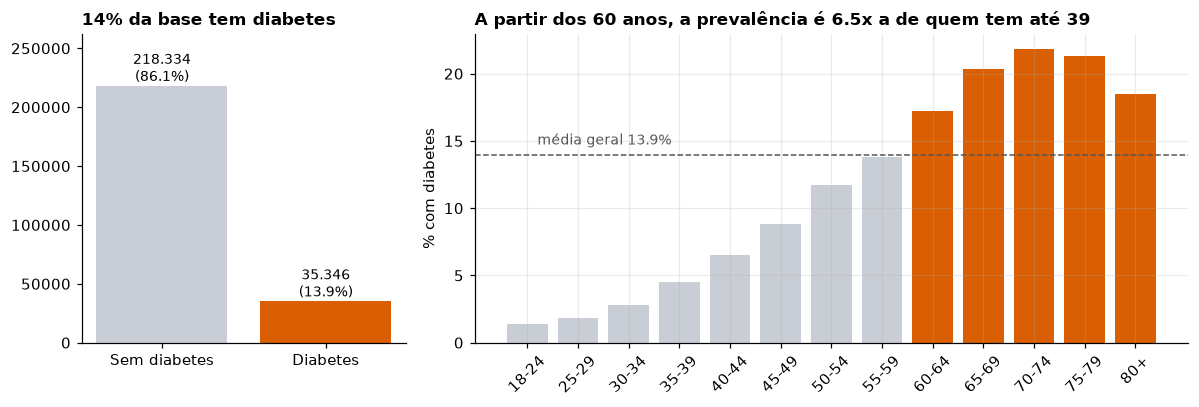

Entre 18 e 39 anos a prevalência é de **3.0%**; a partir dos 60 anos é de **19.7%**, **6.5 vezes** maior.

In [3]:
ROT_IDADE = {1: "18-24", 2: "25-29", 3: "30-34", 4: "35-39", 5: "40-44", 6: "45-49", 7: "50-54",
             8: "55-59", 9: "60-64", 10: "65-69", 11: "70-74", 12: "75-79", 13: "80+"}
prev = bruto.Diabetes_binary.mean()
por_idade = bruto.groupby("Age").Diabetes_binary.agg(["mean", "size"])

jovens = bruto.loc[bruto.Age <= 4, "Diabetes_binary"].mean()
idosos = bruto.loc[bruto.Age >= 9, "Diabetes_binary"].mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 2.2]})
cont = bruto.Diabetes_binary.value_counts().sort_index()
ax[0].bar(["Sem diabetes", "Diabetes"], cont.values, color=[CLARO, LARANJA])
for i, v in enumerate(cont.values):
    ax[0].text(i, v, f"{v:,}\n({v/len(bruto):.1%})".replace(",", "."), ha="center", va="bottom", fontsize=9)
ax[0].set_title(f"{prev:.0%} da base tem diabetes", loc="left")
ax[0].set_ylim(0, cont.max() * 1.2)
ax[0].grid(False)

ax[1].bar([ROT_IDADE[i] for i in por_idade.index], por_idade["mean"] * 100,
          color=[LARANJA if i >= 9 else CLARO for i in por_idade.index])
ax[1].axhline(prev * 100, color="#555", ls="--", lw=1)
ax[1].text(0.2, prev * 100 + 0.8, f"média geral {prev:.1%}", color="#555", fontsize=9)
ax[1].set_title(f"A partir dos 60 anos, a prevalência é {idosos/jovens:.1f}x a de quem tem até 39", loc="left")
ax[1].set_ylabel("% com diabetes")
ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(RES / "01_alvo_idade.png", bbox_inches="tight")
plt.show()

display(Markdown(f"Entre 18 e 39 anos a prevalência é de **{jovens:.1%}**; a partir dos 60 anos é de **{idosos:.1%}**, "
                 f"**{idosos/jovens:.1f} vezes** maior."))

### 2.4 Fatores de risco e hábitos

Com mais de 250 mil linhas, qualquer diferença sai "estatisticamente significativa", então um teste de hipótese não ajuda a escolher o que importa. O critério aqui é o **tamanho do efeito**: o risco relativo (prevalência de quem tem o fator dividida pela de quem não tem).

,fator,% com o fator,diabetes com,diabetes sem,risco relativo
0,HighBP,42.9%,24.4%,6.0%,4.05
1,DiffWalk,16.8%,30.7%,10.5%,2.92
2,HeartDiseaseorAttack,9.4%,33.0%,12.0%,2.76
3,HighChol,42.4%,22.0%,8.0%,2.76
4,Stroke,4.1%,31.8%,13.2%,2.41
5,Smoker,44.3%,16.3%,12.1%,1.35
6,NoDocbcCost,8.4%,17.5%,13.6%,1.29
7,Fruits,63.4%,12.9%,15.8%,0.81
8,Veggies,81.1%,13.0%,18.0%,0.72
9,PhysActivity,75.7%,11.6%,21.1%,0.55


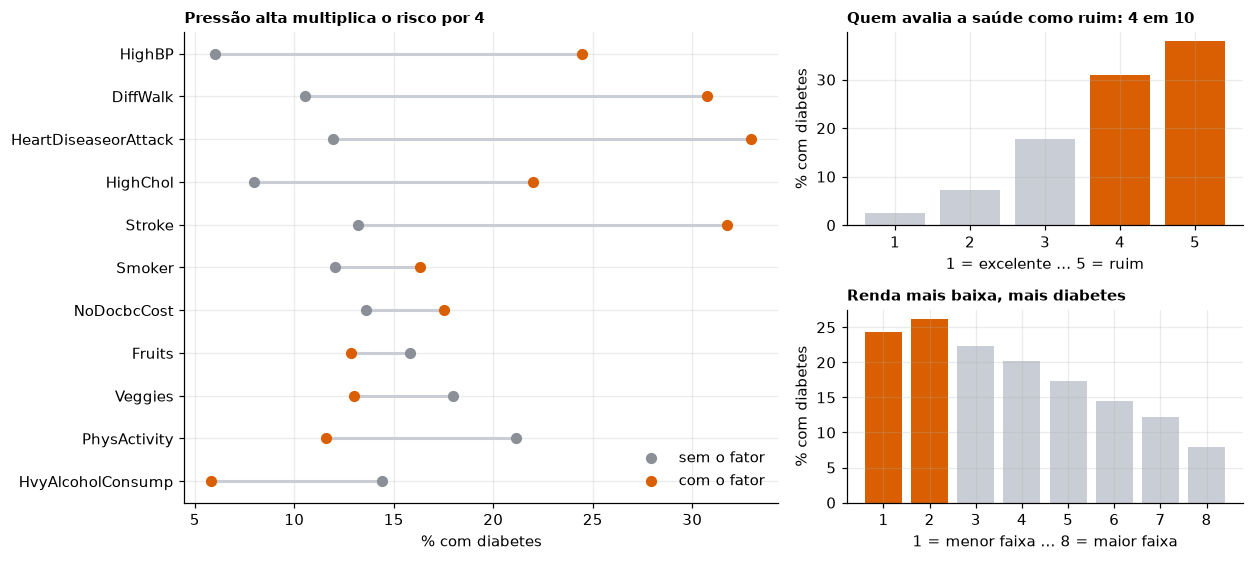

In [4]:
BIN = ["HighBP", "HighChol", "DiffWalk", "HeartDiseaseorAttack", "Stroke", "Smoker",
       "HvyAlcoholConsump", "NoDocbcCost", "PhysActivity", "Fruits", "Veggies"]
linhas = []
for c in BIN:
    com = bruto.loc[bruto[c] == 1, "Diabetes_binary"].mean()
    sem = bruto.loc[bruto[c] == 0, "Diabetes_binary"].mean()
    linhas.append({"fator": c, "% com o fator": bruto[c].mean(), "diabetes com": com, "diabetes sem": sem, "risco relativo": com / sem})
rr = pd.DataFrame(linhas).sort_values("risco relativo", ascending=False).reset_index(drop=True)
display(rr.style.format({"% com o fator": "{:.1%}", "diabetes com": "{:.1%}", "diabetes sem": "{:.1%}", "risco relativo": "{:.2f}"}))

fig = plt.figure(figsize=(11.5, 5.2))
gs = fig.add_gridspec(2, 2, width_ratios=[1.5, 1])
a = fig.add_subplot(gs[:, 0])
ordem = rr.iloc[::-1]
y = np.arange(len(ordem))
a.hlines(y, ordem["diabetes sem"] * 100, ordem["diabetes com"] * 100, color="#c9ced6", lw=2)
a.scatter(ordem["diabetes sem"] * 100, y, color=CINZA, s=40, label="sem o fator", zorder=3)
a.scatter(ordem["diabetes com"] * 100, y, color=LARANJA, s=40, label="com o fator", zorder=3)
a.set_yticks(y)
a.set_yticklabels(ordem["fator"])
a.set_xlabel("% com diabetes")
a.set_title(f"Pressão alta multiplica o risco por {rr.iloc[0]['risco relativo']:.0f}", loc="left", fontsize=10)
a.legend(loc="lower right", frameon=False)

b = fig.add_subplot(gs[0, 1])
g = bruto.groupby("GenHlth").Diabetes_binary.mean() * 100
b.bar(g.index.astype(str), g.values, color=[CLARO] * 3 + [LARANJA] * 2)
b.set_title("Quem avalia a saúde como ruim: 4 em 10", loc="left", fontsize=10)
b.set_xlabel("1 = excelente ... 5 = ruim")
b.set_ylabel("% com diabetes")

c = fig.add_subplot(gs[1, 1])
g = bruto.groupby("Income").Diabetes_binary.mean() * 100
c.bar(g.index.astype(str), g.values, color=[LARANJA] * 2 + [CLARO] * 6)
c.set_title("Renda mais baixa, mais diabetes", loc="left", fontsize=10)
c.set_xlabel("1 = menor faixa ... 8 = maior faixa")
c.set_ylabel("% com diabetes")
plt.tight_layout()
plt.savefig(RES / "02_fatores_risco.png", bbox_inches="tight")
plt.show()

### 2.5 IMC e correlações

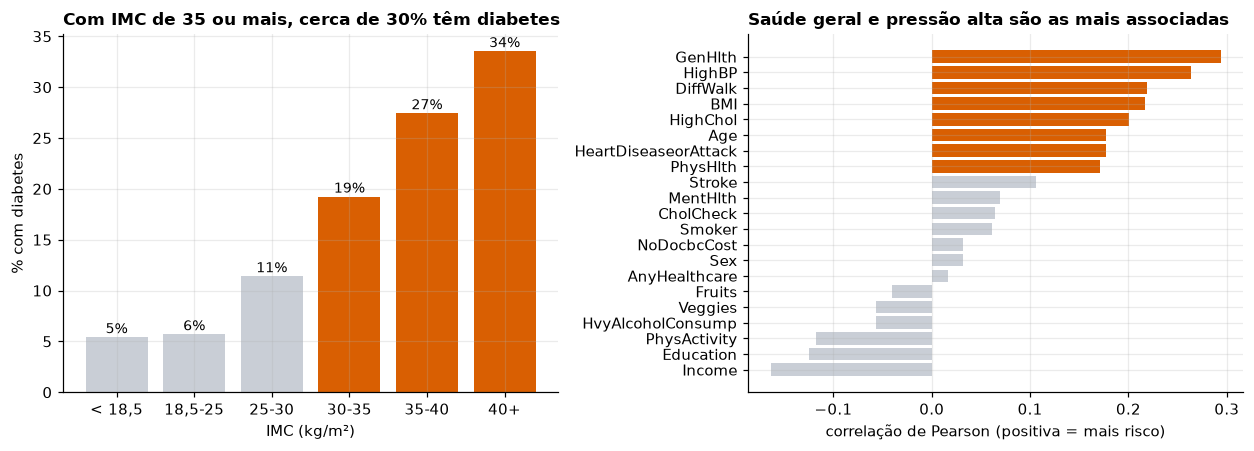

,mean,size
BMI,,
"< 18,5",5.4%,"3,127"
"18,5-25",5.7%,"68,953"
25-30,11.4%,"93,749"
30-35,19.2%,"53,451"
35-40,27.4%,"20,663"
40+,33.5%,"13,737"


In [5]:
faixas = pd.cut(bruto.BMI, [0, 18.5, 25, 30, 35, 40, 200], labels=["< 18,5", "18,5-25", "25-30", "30-35", "35-40", "40+"], right=False)
por_imc = bruto.groupby(faixas, observed=True).Diabetes_binary.agg(["mean", "size"])
corr = bruto[FEATURES_BRUTAS + ["Diabetes_binary"]].corr()["Diabetes_binary"].drop("Diabetes_binary").sort_values()

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax[0].bar(por_imc.index.astype(str), por_imc["mean"] * 100, color=[CLARO] * 3 + [LARANJA] * 3)
for i, (m, n) in enumerate(zip(por_imc["mean"], por_imc["size"])):
    ax[0].text(i, m * 100 + 0.4, f"{m:.0%}", ha="center", fontsize=9)
ax[0].set_title(f"Com IMC de 35 ou mais, cerca de {bruto.loc[bruto.BMI >= 35, 'Diabetes_binary'].mean():.0%} têm diabetes", loc="left")
ax[0].set_xlabel("IMC (kg/m²)")
ax[0].set_ylabel("% com diabetes")
cores = [LARANJA if v > 0.15 else CLARO for v in corr.values]
ax[1].barh(corr.index, corr.values, color=cores)
ax[1].set_title("Saúde geral e pressão alta são as mais associadas", loc="left")
ax[1].set_xlabel("correlação de Pearson (positiva = mais risco)")
plt.tight_layout()
plt.savefig(RES / "03_imc_correlacoes.png", bbox_inches="tight")
plt.show()
display(por_imc.style.format({"mean": "{:.1%}", "size": "{:,.0f}"}))

### 2.6 Síntese da EDA

In [6]:
top_corr = corr.abs().sort_values(ascending=False).head(5)
display(Markdown("**Variáveis mais correlacionadas com o alvo:** " + ", ".join(f"`{k}` ({corr[k]:+.2f})" for k in top_corr.index) + "."))
display(Markdown(f"**Maiores riscos relativos:** " + ", ".join(f"`{r.fator}` ({r['risco relativo']:.1f}x)" for _, r in rr.head(4).iterrows()) + "."))
display(Markdown(f"**Fatores protetores** (risco relativo abaixo de 1): " + ", ".join(f"`{r.fator}` ({r['risco relativo']:.2f}x)" for _, r in rr[rr['risco relativo'] < 1].iterrows()) + "."))

**Variáveis mais correlacionadas com o alvo:** `GenHlth` (+0.29), `HighBP` (+0.26), `DiffWalk` (+0.22), `BMI` (+0.22), `HighChol` (+0.20).

**Maiores riscos relativos:** `HighBP` (4.1x), `DiffWalk` (2.9x), `HeartDiseaseorAttack` (2.8x), `HighChol` (2.8x).

**Fatores protetores** (risco relativo abaixo de 1): `Fruits` (0.81x), `Veggies` (0.72x), `PhysActivity` (0.55x), `HvyAlcoholConsump` (0.40x).

**O que a EDA conta.**

- A **idade** organiza a prevalência: ela cresce de forma contínua até os 70-74 anos e depois recua levemente nas faixas mais velhas.
- Os maiores riscos relativos são **pressão alta, dificuldade para caminhar, doença do coração e colesterol alto**. A saúde geral autoavaliada (`GenHlth`) e o IMC acompanham a prevalência em degraus bem claros.
- A **renda** tem relação inversa com o diabetes: de modo geral, quanto menor a faixa, maior a prevalência.
- Os "fatores protetores" são **associações, não causas**. O consumo pesado de álcool aparece associado a menos diabetes, mas quem recebe o diagnóstico costuma reduzir o álcool (causalidade reversa). O modelo não deve ser lido como recomendação de beber.

## 3. Preparação dos dados (ETL)

**Extração.** Leitura do CSV da UCI (cópia local em `data/raw/`; no Colab, download automático).

**Transformação.**

1. Remover o `ID` (apenas um contador).
2. Converter para tipos pequenos (`int8`/`float32`).
3. Limitar o IMC em 60.
4. Criar `n_condicoes`: quantas das cinco condições de saúde a pessoa relata (pressão alta, colesterol alto, AVC, doença do coração, dificuldade para caminhar).
5. Manter as linhas repetidas (justificativa na seção 2.2).
6. Não aplicar balanceamento por reamostragem. A decisão é por ordenação (quem chamar primeiro), então o desbalanceamento é tratado nas **métricas** (AUC-PR e ganho no topo) e não alterando os dados.

**Carga.** Divisão estratificada em **treino (70%)**, **validação (15%)** e **teste (15%)**, com semente fixa. O teste só é usado uma vez, no fim. Uma mesma função `preparar()` é usada na modelagem e na implantação, para que não exista diferença entre treino e produção.

In [7]:
CONDICOES = ["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack", "DiffWalk"]

def preparar(df):
    """Transformações únicas do ETL; recebe linhas no formato da pesquisa e devolve só as variáveis do modelo."""
    X = df[FEATURES_BRUTAS].copy()
    X["BMI"] = X["BMI"].clip(upper=60)
    X["n_condicoes"] = X[CONDICOES].sum(axis=1)
    return X.astype("float32")

X = preparar(bruto)
y = bruto["Diabetes_binary"].astype("int8").to_numpy()
FEATURES = list(X.columns)

X_tv, X_te, y_tv, y_te = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)
X_tr, X_va, y_tr, y_va = train_test_split(X_tv, y_tv, test_size=0.15 / 0.85, stratify=y_tv, random_state=SEED)

part = pd.DataFrame({
    "partição": ["treino", "validação", "teste"],
    "linhas": [len(y_tr), len(y_va), len(y_te)],
    "casos de diabetes": [int(y_tr.sum()), int(y_va.sum()), int(y_te.sum())],
    "prevalência": [y_tr.mean(), y_va.mean(), y_te.mean()],
})
part.to_csv(RES / "particoes.csv", index=False)
display(part.style.format({"linhas": "{:,.0f}", "casos de diabetes": "{:,.0f}", "prevalência": "{:.2%}"}))
print("Variáveis do modelo:", len(FEATURES), "->", FEATURES)

,partição,linhas,casos de diabetes,prevalência
0,treino,"177,576","24,742",13.93%
1,validação,"38,052","5,302",13.93%
2,teste,"38,052","5,302",13.93%


Variáveis do modelo: 22 -> ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'n_condicoes']


## 4. Modelagem (análise preditiva)

**Métrica principal.** Como o uso é priorizar uma lista, interessa o **ganho no topo**: a fração dos casos que aparece entre os 20% de maior risco (`captura@20%`) e o **lift** (captura dividida por 20%). A seleção entre modelos usa a **AUC-PR** (precisão média), mais honesta que a AUC-ROC com 14% de positivos.

**Candidatos:**

- **Base ingênua:** nota igual para todos (equivale ao acaso).
- **Regra simples por idade:** quanto mais velho, maior a prioridade (a alternativa que a gestão usaria sem modelo).
- **Regressão logística:** modelo linear, fácil de explicar.
- **Random forest** e **HistGradientBoosting**, com poucos ajustes de hiperparâmetros escolhidos na validação.

In [8]:
CAPACIDADE = 0.20      # fração da população que cabe nos exames de um ciclo
LIFT_MINIMO = 2.0      # critério de sucesso 1 (seção 1)

def captura_topo(y_true, score, frac=CAPACIDADE):
    """Fração dos casos que cai entre os `frac` de maior nota; precisão no topo; lift."""
    k = int(np.ceil(len(y_true) * frac))
    idx = np.argsort(-score, kind="stable")[:k]
    cap = y_true[idx].sum() / y_true.sum()
    return cap, y_true[idx].mean(), cap / frac

def avaliar(y_true, score):
    cap, prec, lift = captura_topo(y_true, score)
    return {"AUC-ROC": roc_auc_score(y_true, score), "AUC-PR": average_precision_score(y_true, score),
            "captura@20%": cap, "precisão@20%": prec, "lift@20%": lift}

def nota_regra_idade(X_):
    """Regra simples: ordena por faixa etária, desempate aleatório dentro da faixa."""
    return X_["Age"].to_numpy() + RNG.uniform(0, 0.5, len(X_))

candidatos = {
    "Base ingênua": DummyClassifier(strategy="prior"),
    "Regressão logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=40, max_features="sqrt", n_jobs=-1, random_state=SEED),
}
for lr in (0.05, 0.1):
    for folhas in (15, 31):
        for l2 in (0.0, 5.0):
            candidatos[f"HGB lr={lr} folhas={folhas} l2={l2}"] = HistGradientBoostingClassifier(
                learning_rate=lr, max_leaf_nodes=folhas, l2_regularization=l2, max_iter=400,
                early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=SEED)

resultados_val = {"Regra simples por idade": avaliar(y_va, nota_regra_idade(X_va))}
notas_val = {}
for nome, modelo in candidatos.items():
    modelo.fit(X_tr, y_tr)
    notas_val[nome] = modelo.predict_proba(X_va)[:, 1] + RNG.uniform(0, 1e-9, len(y_va))
    resultados_val[nome] = avaliar(y_va, notas_val[nome])

tab_val = pd.DataFrame(resultados_val).T.sort_values("AUC-PR", ascending=False)
tab_val.to_csv(RES / "metricas_validacao.csv")
display(tab_val.style.format("{:.4f}"))

,AUC-ROC,AUC-PR,captura@20%,precisão@20%,lift@20%
HGB lr=0.05 folhas=31 l2=0.0,0.8337,0.4410,0.5841,0.4069,2.9206
HGB lr=0.1 folhas=31 l2=5.0,0.8339,0.4410,0.5843,0.4070,2.9215
HGB lr=0.05 folhas=31 l2=5.0,0.8337,0.4407,0.5853,0.4077,2.9263
HGB lr=0.1 folhas=31 l2=0.0,0.8333,0.4398,0.5832,0.4063,2.9159
HGB lr=0.1 folhas=15 l2=5.0,0.8334,0.4398,0.5828,0.4060,2.9140
HGB lr=0.05 folhas=15 l2=5.0,0.8335,0.4397,0.5839,0.4068,2.9197
HGB lr=0.05 folhas=15 l2=0.0,0.8334,0.4391,0.5817,0.4052,2.9083
HGB lr=0.1 folhas=15 l2=0.0,0.8330,0.4390,0.5826,0.4059,2.9131
Random forest,0.8293,0.4355,0.5794,0.4036,2.8970
Regressão logística,0.8262,0.4203,0.5666,0.3947,2.8329


### 4.1 Seleção do modelo

In [9]:
elegiveis = tab_val.drop(index=["Base ingênua", "Regra simples por idade"])
vencedor = elegiveis["AUC-PR"].idxmax()
print("Vencedor na validação (maior AUC-PR):", vencedor)
display(Markdown(f"A **{vencedor}** tem AUC-PR de **{elegiveis.loc[vencedor, 'AUC-PR']:.4f}** na validação. "
                 f"A regressão logística fica em **{elegiveis.loc['Regressão logística', 'AUC-PR']:.4f}**, "
                 f"uma diferença de **{elegiveis.loc[vencedor, 'AUC-PR'] - elegiveis.loc['Regressão logística', 'AUC-PR']:+.4f}**. "
                 f"O lift@20% do vencedor é **{elegiveis.loc[vencedor, 'lift@20%']:.2f}** e o da regra por idade é "
                 f"**{tab_val.loc['Regra simples por idade', 'lift@20%']:.2f}**."))

Vencedor na validação (maior AUC-PR): HGB lr=0.05 folhas=31 l2=0.0


A **HGB lr=0.05 folhas=31 l2=0.0** tem AUC-PR de **0.4410** na validação. A regressão logística fica em **0.4203**, uma diferença de **+0.0208**. O lift@20% do vencedor é **2.92** e o da regra por idade é **1.55**.

**Leitura.** As oito variações do HistGradientBoosting ficam praticamente empatadas (a diferença entre elas é menor que a incerteza do próprio teste), então os hiperparâmetros importam pouco aqui. A distância para a regressão logística é pequena: se a explicabilidade pesar mais que o último ponto de desempenho, a logística é uma alternativa defensável. Mantenho a regra definida antes (maior AUC-PR na validação). A **regra simples por idade** fica bem atrás de todos os modelos.

Após escolher o modelo, o **reajusto com treino e validação juntos** (mais dados) e uso o conjunto de **teste** uma única vez.

## 5. Avaliação

### 5.1 Resultado no teste

In [10]:
final = clone(candidatos[vencedor]).fit(pd.concat([X_tr, X_va]), np.concatenate([y_tr, y_va]))
nota_te = final.predict_proba(X_te)[:, 1] + RNG.uniform(0, 1e-9, len(y_te))
nota_regra = nota_regra_idade(X_te)
nota_acaso = RNG.uniform(0, 1, len(y_te))

teste = pd.DataFrame({
    "Modelo escolhido": avaliar(y_te, nota_te),
    "Regra simples por idade": avaliar(y_te, nota_regra),
    "Seleção aleatória": avaliar(y_te, nota_acaso),
}).T
teste.to_csv(RES / "metricas_teste.csv")
display(teste.style.format("{:.4f}"))

# Intervalo de confiança por bootstrap (500 reamostragens do teste)
boot = []
n = len(y_te)
for _ in range(500):
    i = RNG.integers(0, n, n)
    a = avaliar(y_te[i], nota_te[i])
    r = avaliar(y_te[i], nota_regra[i])
    boot.append({"AUC-PR": a["AUC-PR"], "captura@20%": a["captura@20%"], "lift@20%": a["lift@20%"],
                 "ganho sobre a regra (captura)": a["captura@20%"] - r["captura@20%"]})
ic = pd.DataFrame(boot).quantile([0.025, 0.975]).T
ic.columns = ["IC95% inferior", "IC95% superior"]
ic["estimativa"] = [teste.loc["Modelo escolhido", "AUC-PR"], teste.loc["Modelo escolhido", "captura@20%"],
                    teste.loc["Modelo escolhido", "lift@20%"],
                    teste.loc["Modelo escolhido", "captura@20%"] - teste.loc["Regra simples por idade", "captura@20%"]]
ic = ic[["estimativa", "IC95% inferior", "IC95% superior"]]
ic.to_csv(RES / "intervalos_confianca.csv")
display(ic.style.format("{:.4f}"))

,AUC-ROC,AUC-PR,captura@20%,precisão@20%,lift@20%
Modelo escolhido,0.8276,0.4210,0.5664,0.3946,2.8320
Regra simples por idade,0.6465,0.1912,0.2857,0.1991,1.4287
Seleção aleatória,0.5021,0.1391,0.1948,0.1357,0.9742


,estimativa,IC95% inferior,IC95% superior
AUC-PR,0.4210,0.4083,0.4348
captura@20%,0.5664,0.5553,0.5796
lift@20%,2.8320,2.7765,2.8980
ganho sobre a regra (captura),0.2806,0.2651,0.2977


### 5.2 Ganho acumulado e decis de risco

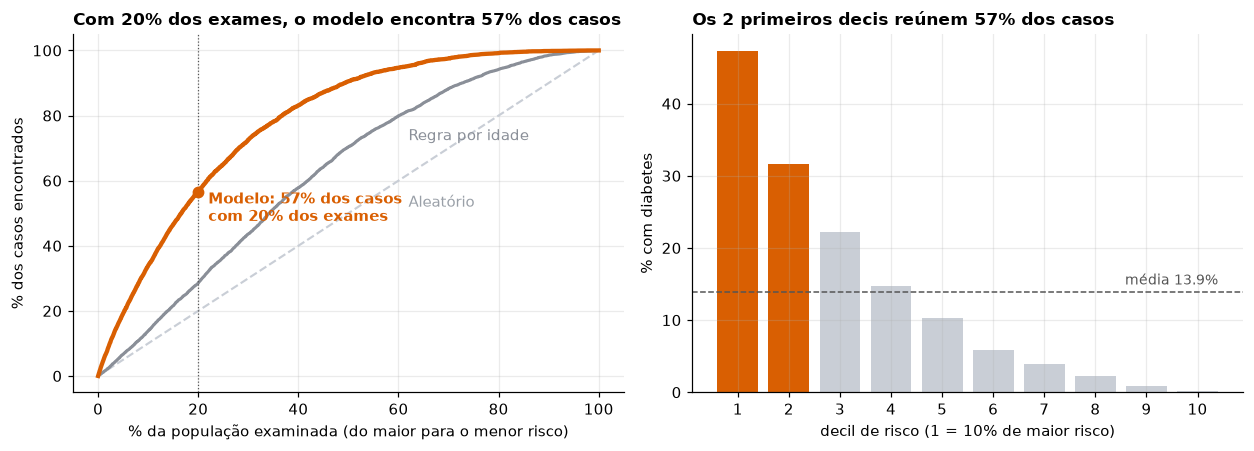

,pessoas,casos,prevalência,nota_média,% dos casos,captura acumulada,lift do decil
decil,,,,,,,
1,"3,806","1,799",47.3%,0.494,33.9%,33.9%,3.39
2,"3,805","1,204",31.6%,0.312,22.7%,56.6%,2.27
3,"3,805",847,22.3%,0.212,16.0%,72.6%,1.60
4,"3,805",559,14.7%,0.144,10.5%,83.2%,1.05
5,"3,805",390,10.2%,0.097,7.4%,90.5%,0.74
6,"3,805",221,5.8%,0.061,4.2%,94.7%,0.42
7,"3,805",151,4.0%,0.037,2.8%,97.5%,0.28
8,"3,805",88,2.3%,0.020,1.7%,99.2%,0.17
9,"3,805",34,0.9%,0.010,0.6%,99.8%,0.06


In [11]:
def curva_ganho(y_true, score):
    ordem = np.argsort(-score, kind="stable")
    cum = np.cumsum(y_true[ordem]) / y_true.sum()
    return np.arange(1, len(y_true) + 1) / len(y_true), cum

x_m, g_m = curva_ganho(y_te, nota_te)
x_r, g_r = curva_ganho(y_te, nota_regra)

dec = pd.DataFrame({"y": y_te, "s": nota_te})
dec["decil"] = pd.qcut(dec["s"].rank(method="first", ascending=False), 10, labels=range(1, 11)).astype(int)
tab_dec = dec.groupby("decil").agg(pessoas=("y", "size"), casos=("y", "sum"), prevalência=("y", "mean"), nota_média=("s", "mean"))
tab_dec["% dos casos"] = tab_dec["casos"] / tab_dec["casos"].sum()
tab_dec["captura acumulada"] = tab_dec["% dos casos"].cumsum()
tab_dec["lift do decil"] = tab_dec["prevalência"] / y_te.mean()
tab_dec.to_csv(RES / "decis_de_risco.csv")

cap_m = captura_topo(y_te, nota_te)[0]
top2 = tab_dec["% dos casos"].iloc[:2].sum()
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax[0].plot([0, 100], [0, 100], color=CLARO, ls="--", lw=1.4)
ax[0].plot(x_r * 100, g_r * 100, color=CINZA, lw=2)
ax[0].plot(x_m * 100, g_m * 100, color=LARANJA, lw=2.8)
ax[0].axvline(CAPACIDADE * 100, color="#555", lw=0.8, ls=":")
ax[0].scatter([CAPACIDADE * 100], [cap_m * 100], color=LARANJA, zorder=5, s=45)
ax[0].text(CAPACIDADE * 100 + 2, cap_m * 100 - 9, f"Modelo: {cap_m:.0%} dos casos\ncom 20% dos exames", color=LARANJA, fontsize=9.5, fontweight="bold")
ax[0].text(62, np.interp(62, x_r * 100, g_r * 100) - 9, "Regra por idade", color=CINZA, fontsize=9.5)
ax[0].text(62, 52, "Aleatório", color="#9aa0a8", fontsize=9.5, rotation=0)
ax[0].set_xlabel("% da população examinada (do maior para o menor risco)")
ax[0].set_ylabel("% dos casos encontrados")
ax[0].set_title(f"Com 20% dos exames, o modelo encontra {cap_m:.0%} dos casos", loc="left")

ax[1].bar(tab_dec.index.astype(str), tab_dec["prevalência"] * 100, color=[LARANJA] * 2 + [CLARO] * 8)
ax[1].axhline(y_te.mean() * 100, color="#555", ls="--", lw=1)
ax[1].text(9.4, y_te.mean() * 100 + 1, f"média {y_te.mean():.1%}", color="#555", ha="right", fontsize=9)
ax[1].set_xlabel("decil de risco (1 = 10% de maior risco)")
ax[1].set_ylabel("% com diabetes")
ax[1].set_title(f"Os 2 primeiros decis reúnem {top2:.0%} dos casos", loc="left")
plt.tight_layout()
plt.savefig(RES / "04_ganho_decis.png", bbox_inches="tight")
plt.show()
display(tab_dec.style.format({"pessoas": "{:,.0f}", "casos": "{:,.0f}", "prevalência": "{:.1%}", "nota_média": "{:.3f}",
                              "% dos casos": "{:.1%}", "captura acumulada": "{:.1%}", "lift do decil": "{:.2f}"}))

### 5.3 O que pesa no modelo e como ele se comporta em subgrupos

A importância por permutação mede quanto a AUC-PR cai quando uma variável é embaralhada. É uma leitura de **associação**, não de causa.

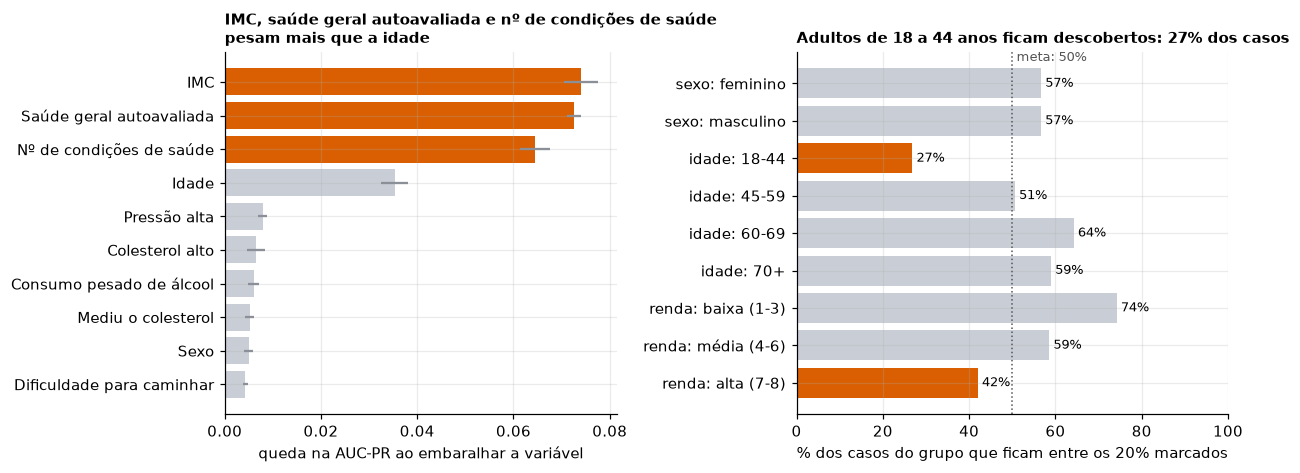

,variável,queda na AUC-PR,desvio
0,BMI,0.0740,0.0036
1,GenHlth,0.0726,0.0014
2,n_condicoes,0.0644,0.0031
3,Age,0.0353,0.0028
4,HighBP,0.0079,0.0009
5,HighChol,0.0065,0.0019
6,HvyAlcoholConsump,0.0060,0.0011
7,CholCheck,0.0052,0.0010
8,Sex,0.0050,0.0010
9,DiffWalk,0.0043,0.0005


,grupo,pessoas,prevalência,% marcado,cobertura dos casos,precisão
0,sexo: feminino,"21,317",12.8%,18.3%,56.7%,39.7%
1,sexo: masculino,"16,735",15.4%,22.2%,56.6%,39.2%
2,idade: 18-44,"8,232",4.2%,2.7%,26.8%,41.2%
3,idade: 45-59,"11,372",11.5%,14.5%,50.6%,40.2%
4,idade: 60-69,"9,806",19.1%,29.9%,64.2%,41.1%
5,idade: 70+,"8,642",20.5%,32.5%,58.9%,37.2%
6,renda: baixa (1-3),"5,561",24.5%,41.5%,74.2%,43.8%
7,renda: média (4-6),"12,350",16.5%,25.4%,58.5%,38.1%
8,renda: alta (7-8),"20,141",9.4%,10.8%,42.0%,36.7%


In [12]:
amostra = RNG.choice(len(y_te), 25000, replace=False)
perm = permutation_importance(final, X_te.iloc[amostra], y_te[amostra], scoring="average_precision",
                              n_repeats=5, random_state=SEED, n_jobs=-1)
NOMES_PT = {"BMI": "IMC", "GenHlth": "Saúde geral autoavaliada", "n_condicoes": "Nº de condições de saúde", "Age": "Idade",
            "HighBP": "Pressão alta", "HighChol": "Colesterol alto", "HvyAlcoholConsump": "Consumo pesado de álcool",
            "CholCheck": "Mediu o colesterol", "Sex": "Sexo", "DiffWalk": "Dificuldade para caminhar", "Income": "Renda",
            "Education": "Escolaridade", "PhysHlth": "Dias de saúde física ruim", "MentHlth": "Dias de saúde mental ruim",
            "Smoker": "Fumante", "Stroke": "AVC", "HeartDiseaseorAttack": "Doença do coração", "PhysActivity": "Atividade física",
            "Fruits": "Come frutas", "Veggies": "Come verduras", "AnyHealthcare": "Tem cobertura de saúde", "NoDocbcCost": "Evitou médico por custo"}
imp = pd.DataFrame({"variável": FEATURES, "queda na AUC-PR": perm.importances_mean, "desvio": perm.importances_std})
imp = imp.sort_values("queda na AUC-PR", ascending=False).reset_index(drop=True)
imp.to_csv(RES / "importancia_variaveis.csv", index=False)

# Subgrupos: mesma nota de corte global (20% de maior nota no teste)
corte = np.sort(nota_te)[::-1][int(np.ceil(len(y_te) * CAPACIDADE)) - 1]
sub = X_te.copy()
sub["y"], sub["marcado"] = y_te, nota_te >= corte
sub["idade"] = pd.cut(sub["Age"], [0, 5, 8, 10, 13], labels=["18-44", "45-59", "60-69", "70+"])
sub["renda"] = pd.cut(sub["Income"], [0, 3, 6, 8], labels=["baixa (1-3)", "média (4-6)", "alta (7-8)"])
sub["sexo"] = sub["Sex"].map({0.0: "feminino", 1.0: "masculino"})
linhas = []
for col in ["sexo", "idade", "renda"]:
    for nome, g in sub.groupby(col, observed=True):
        casos = g["y"].sum()
        linhas.append({"grupo": f"{col}: {nome}", "pessoas": len(g), "prevalência": g["y"].mean(),
                       "% marcado": g["marcado"].mean(), "cobertura dos casos": g.loc[g["y"] == 1, "marcado"].mean(),
                       "precisão": g.loc[g["marcado"], "y"].mean() if g["marcado"].any() else np.nan})
tab_sub = pd.DataFrame(linhas)
tab_sub.to_csv(RES / "subgrupos.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})
top = imp.head(10).iloc[::-1]
ax[0].barh(top["variável"].map(NOMES_PT), top["queda na AUC-PR"], xerr=top["desvio"],
           color=[CLARO] * 7 + [LARANJA] * 3, ecolor=CINZA)
n1, n2, n3 = (NOMES_PT[v] for v in imp["variável"].head(3))
ax[0].set_title(f"{n1}, {n2.lower()} e {n3.lower()}\npesam mais que a idade", loc="left", fontsize=10)
ax[0].set_xlabel("queda na AUC-PR ao embaralhar a variável")
yy = np.arange(len(tab_sub))[::-1]
ax[1].barh(yy, tab_sub["cobertura dos casos"] * 100, color=[LARANJA if v < 0.5 else CLARO for v in tab_sub["cobertura dos casos"]])
ax[1].axvline(50, color="#555", ls=":", lw=1)
ax[1].text(51, len(tab_sub) - 0.4, "meta: 50%", color="#555", fontsize=8.5)
for yv, v in zip(yy, tab_sub["cobertura dos casos"]):
    ax[1].text(v * 100 + 1, yv, f"{v:.0%}", va="center", fontsize=8.5)
ax[1].set_yticks(yy)
ax[1].set_yticklabels(tab_sub["grupo"])
ax[1].set_xlim(0, 100)
ax[1].set_xlabel("% dos casos do grupo que ficam entre os 20% marcados")
ax[1].set_title(f"Adultos de 18 a 44 anos ficam descobertos: {tab_sub.set_index('grupo').loc['idade: 18-44', 'cobertura dos casos']:.0%} dos casos", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig(RES / "05_importancia_subgrupos.png", bbox_inches="tight")
plt.show()
display(imp.head(10).style.format({"queda na AUC-PR": "{:.4f}", "desvio": "{:.4f}"}))
display(tab_sub.style.format({"pessoas": "{:,.0f}", "prevalência": "{:.1%}", "% marcado": "{:.1%}", "cobertura dos casos": "{:.1%}", "precisão": "{:.1%}"}))

### 5.4 Verificação dos critérios de sucesso

In [13]:
cap_mod, prec_mod, lift_mod = captura_topo(y_te, nota_te)
cap_reg = captura_topo(y_te, nota_regra)[0]
menor_cob = tab_sub["cobertura dos casos"].min()
pior_grupo = tab_sub.loc[tab_sub["cobertura dos casos"].idxmin(), "grupo"]
criterios = pd.DataFrame([
    ("1. Lift@20% >= 2,0", f"{lift_mod:.2f}", lift_mod >= LIFT_MINIMO),
    ("2. Supera a regra por idade (captura@20%)", f"{cap_mod:.1%} contra {cap_reg:.1%}", cap_mod > cap_reg),
    ("3. Nenhum subgrupo com cobertura abaixo de 50%", f"menor: {menor_cob:.1%} ({pior_grupo})", menor_cob >= 0.5),
], columns=["critério", "resultado", "atendido"])
criterios["atendido"] = criterios["atendido"].map({True: "sim", False: "não"})
display(criterios)

,critério,resultado,atendido
0,"1. Lift@20% >= 2,0",2.83,sim
1,2. Supera a regra por idade (captura@20%),56.6% contra 28.6%,sim
2,3. Nenhum subgrupo com cobertura abaixo de 50%,menor: 26.8% (idade: 18-44),não


In [14]:
g = tab_sub.set_index("grupo")
display(Markdown(
    f"**Subgrupos.** Entre homens e mulheres a cobertura é praticamente igual ({g.loc['sexo: feminino', 'cobertura dos casos']:.1%} e "
    f"{g.loc['sexo: masculino', 'cobertura dos casos']:.1%}). A diferença está na **idade** e na **renda**. "
    f"Entre 18 e 44 anos só **{g.loc['idade: 18-44', 'cobertura dos casos']:.1%}** dos casos ficam entre os 20% marcados "
    f"(prevalência de {g.loc['idade: 18-44', 'prevalência']:.1%}), e na renda alta a cobertura é de "
    f"**{g.loc['renda: alta (7-8)', 'cobertura dos casos']:.1%}**, contra **{g.loc['renda: baixa (1-3)', 'cobertura dos casos']:.1%}** na renda baixa. "
    f"Com um corte único para todos, o modelo concentra a lista nas pessoas mais velhas e de menor renda, onde há mais casos, e deixa passar "
    f"os casos mais raros de quem é jovem e de renda alta. Isso explica por que o **critério 3 não foi atendido**."
))

**Subgrupos.** Entre homens e mulheres a cobertura é praticamente igual (56.7% e 56.6%). A diferença está na **idade** e na **renda**. Entre 18 e 44 anos só **26.8%** dos casos ficam entre os 20% marcados (prevalência de 4.2%), e na renda alta a cobertura é de **42.0%**, contra **74.2%** na renda baixa. Com um corte único para todos, o modelo concentra a lista nas pessoas mais velhas e de menor renda, onde há mais casos, e deixa passar os casos mais raros de quem é jovem e de renda alta. Isso explica por que o **critério 3 não foi atendido**.

**Leitura dos critérios.** Os critérios 1 e 2 foram atendidos com folga. O critério 3 **não** foi: o modelo funciona bem para o público onde o diabetes é mais comum, mas cobre pouco os casos em adultos jovens. Isso não invalida o uso, mas muda a recomendação: o modelo serve para a fila principal e precisa de uma **ação complementar para os mais jovens** (seção 6).

## 6. Implantação e data storytelling

### 6.1 Como o modelo seria usado

In [15]:
# Capacidade necessária para alcançar metas de cobertura (calculado no teste)
ordem = np.argsort(-nota_te, kind="stable")
cum = np.cumsum(y_te[ordem]) / y_te.sum()
metas = pd.DataFrame({"meta de casos encontrados": [0.5, 0.6, 0.7, 0.8, 0.9]})
metas["% da população examinada"] = [(np.searchsorted(cum, m) + 1) / len(y_te) for m in metas["meta de casos encontrados"]]
ordem_r = np.argsort(-nota_regra, kind="stable")
cum_r = np.cumsum(y_te[ordem_r]) / y_te.sum()
metas["% examinada (regra por idade)"] = [(np.searchsorted(cum_r, m) + 1) / len(y_te) for m in metas["meta de casos encontrados"]]
metas.to_csv(RES / "capacidade_necessaria.csv", index=False)
display(metas.style.format({"meta de casos encontrados": "{:.0%}", "% da população examinada": "{:.1%}", "% examinada (regra por idade)": "{:.1%}"}))

# Casos encontrados a cada 1.000 pessoas examinadas
por_mil = pd.DataFrame({
    "estratégia": ["Aleatória", "Regra por idade", "Modelo"],
    "casos por 1.000 examinados": [y_te.mean() * 1000, captura_topo(y_te, nota_regra)[1] * 1000, prec_mod * 1000],
})
display(por_mil.style.format({"casos por 1.000 examinados": "{:.0f}"}))
resumo_pop80 = (float(metas.loc[metas["meta de casos encontrados"] == 0.8, "% da população examinada"].iloc[0]),
                float(metas.loc[metas["meta de casos encontrados"] == 0.8, "% examinada (regra por idade)"].iloc[0]))

# Artefato de produção: modelo, variáveis e corte
corte_prod = float(corte)
joblib.dump({"modelo": final, "variaveis": FEATURES, "corte_top20": corte_prod, "capacidade": CAPACIDADE,
             "sklearn": sklearn.__version__}, RES / "modelo.joblib")

def priorizar(df_novo, modelo_path=RES / "modelo.joblib"):
    """Recebe respostas no formato da pesquisa e devolve cada pessoa com nota e prioridade (1 = maior risco)."""
    art = joblib.load(modelo_path)
    nota = art["modelo"].predict_proba(preparar(df_novo)[art["variaveis"]])[:, 1]
    out = df_novo.copy()
    out["nota_risco"] = nota
    out["prioridade"] = pd.Series(nota, index=out.index).rank(ascending=False, method="first").astype(int)
    out["examinar_neste_ciclo"] = nota >= art["corte_top20"]
    return out.sort_values("prioridade")

exemplo = priorizar(bruto.sample(1000, random_state=SEED))
print(f"Em 1.000 pessoas sorteadas, {int(exemplo['examinar_neste_ciclo'].sum())} ficam marcadas para exame neste ciclo.")
exemplo[["Age", "BMI", "HighBP", "GenHlth", "nota_risco", "prioridade", "examinar_neste_ciclo"]].head(5)

,meta de casos encontrados,% da população examinada,% examinada (regra por idade)
0,50%,16.6%,34.2%
1,60%,21.7%,41.8%
2,70%,28.1%,49.6%
3,80%,36.7%,60.1%
4,90%,49.2%,72.7%


,estratégia,casos por 1.000 examinados
0,Aleatória,139
1,Regra por idade,199
2,Modelo,395


Em 1.000 pessoas sorteadas, 200 ficam marcadas para exame neste ciclo.


,Age,BMI,HighBP,GenHlth,nota_risco,prioridade,examinar_neste_ciclo
88432,9,49,1,5,0.760169,1,True
253464,10,41,1,5,0.758557,2,True
85893,11,47,1,4,0.725461,3,True
251353,10,45,1,4,0.702275,4,True
208959,10,50,1,4,0.699777,5,True


### 6.2 Qual é o impacto?

"Lift de 2,8" não diz o que muda para quem decide. Aqui o resultado é traduzido em **casos encontrados, exames necessários e custo por caso** para uma população de 100 mil adultos, comparando o cenário inercial (convocar por idade) com a intervenção (convocar pela nota de risco).

**Premissas (hipóteses ajustáveis, não dados da pesquisa):**

- População acompanhada de 100.000 adultos, com a prevalência da pesquisa. Em outra região, escale pelo número de casos esperado.
- Capacidade de 20% da população por ciclo (20.000 exames).
- Custo de **R$ 1,85 por exame**: valor do procedimento "dosagem de glicose" (código 02.02.01.047-3) na tabela SUS (SIGTAP), segundo tabelas municipais recentes (confira a competência vigente no DATASUS). É só o pagamento do exame: coleta, logística e convocação não entram na conta. No setor privado os preços variam bastante (cerca de R$ 6 a R$ 23, segundo tabelas de sites de conteúdo, fonte fraca), por isso há uma sensibilidade abaixo.
- "Caso encontrado" é a pessoa com diabetes ou pré-diabetes que chega ao exame. O **benefício clínico** de achar o caso mais cedo não foi estimado; só o custo dos exames entra na conta.

In [16]:
POP, CUSTO_EXAME = 100_000, 1.85
rng2 = np.random.default_rng(SEED + 1)   # gerador próprio: não altera os sorteios anteriores
estrategias = {"Aleatória": nota_acaso, "Regra por idade": nota_regra, "Modelo": nota_te}
casos_pop = POP * float(y.mean())
exames_ciclo = POP * CAPACIDADE

# Incerteza: 500 reamostragens do teste (as três estratégias são comparadas nas mesmas reamostras)
boot2 = {k: [] for k in estrategias}
for _ in range(500):
    i = rng2.integers(0, len(y_te), len(y_te))
    for k, s in estrategias.items():
        boot2[k].append(captura_topo(y_te[i], s[i])[0])
boot2 = {k: np.array(v) for k, v in boot2.items()}

linhas = []
for k, s in estrategias.items():
    cap = captura_topo(y_te, s)[0]
    lo, hi = np.quantile(boot2[k], [0.025, 0.975])
    casos = casos_pop * cap
    linhas.append({"estratégia": k, "exames": exames_ciclo, "casos encontrados": casos,
                   "IC95% inferior": casos_pop * lo, "IC95% superior": casos_pop * hi,
                   "exames por caso": exames_ciclo / casos, "custo por caso (R$)": exames_ciclo * CUSTO_EXAME / casos})
impacto = pd.DataFrame(linhas).set_index("estratégia")
extra_casos = impacto.loc["Modelo", "casos encontrados"] - impacto.loc["Regra por idade", "casos encontrados"]
lo_e, hi_e = np.quantile(casos_pop * (boot2["Modelo"] - boot2["Regra por idade"]), [0.025, 0.975])

exames_80_m, exames_80_r = POP * resumo_pop80[0], POP * resumo_pop80[1]
economia_ex = exames_80_r - exames_80_m
economia_pct = economia_ex / exames_80_r
impacto.to_csv(RES / "impacto_por_100mil.csv")
display(impacto.style.format({"exames": "{:,.0f}", "casos encontrados": "{:,.0f}", "IC95% inferior": "{:,.0f}", "IC95% superior": "{:,.0f}",
                              "exames por caso": "{:.1f}", "custo por caso (R$)": "{:.2f}"}))
print(f"Casos a mais que a regra por idade: {extra_casos:,.0f} (IC95% {lo_e:,.0f} a {hi_e:,.0f}) por ciclo, a cada {POP:,} adultos.")
print(f"Para encontrar 80% dos casos: {exames_80_m:,.0f} exames contra {exames_80_r:,.0f} pela regra por idade "
      f"({economia_ex:,.0f} exames a menos, {economia_pct:.0%}; R$ {economia_ex * CUSTO_EXAME:,.0f} a menos a R$ {br(CUSTO_EXAME, 2)} por exame).")

# Sensibilidade: custo do exame e tamanho da capacidade
sens_custo = pd.DataFrame({"custo por exame (R$)": [1.85, 6.0, 15.0, 23.0]})
sens_custo["economia por ciclo para achar 80% dos casos (R$)"] = sens_custo["custo por exame (R$)"] * economia_ex
sens_custo["custo por caso, modelo (R$)"] = sens_custo["custo por exame (R$)"] * impacto.loc["Modelo", "exames por caso"]
sens_custo["custo por caso, regra por idade (R$)"] = sens_custo["custo por exame (R$)"] * impacto.loc["Regra por idade", "exames por caso"]
sens_cap = pd.DataFrame({"capacidade": [0.10, 0.20, 0.30, 0.40]})
sens_cap["casos encontrados, modelo"] = [casos_pop * captura_topo(y_te, nota_te, f)[0] for f in sens_cap["capacidade"]]
sens_cap["casos encontrados, regra por idade"] = [casos_pop * captura_topo(y_te, nota_regra, f)[0] for f in sens_cap["capacidade"]]
sens_cap["casos a mais com o modelo"] = sens_cap["casos encontrados, modelo"] - sens_cap["casos encontrados, regra por idade"]
sens_custo.to_csv(RES / "sensibilidade_custo.csv", index=False)
sens_cap.to_csv(RES / "sensibilidade_capacidade.csv", index=False)
display(sens_custo.style.format({"custo por exame (R$)": "{:.2f}", "economia por ciclo para achar 80% dos casos (R$)": "{:,.0f}",
                                 "custo por caso, modelo (R$)": "{:.2f}", "custo por caso, regra por idade (R$)": "{:.2f}"}))
display(sens_cap.style.format({"capacidade": "{:.0%}", "casos encontrados, modelo": "{:,.0f}", "casos encontrados, regra por idade": "{:,.0f}", "casos a mais com o modelo": "{:,.0f}"}))

,exames,casos encontrados,IC95% inferior,IC95% superior,exames por caso,custo por caso (R$)
estratégia,,,,,,
Aleatória,"20,000","2,715","2,582","2,860",7.4,13.63
Regra por idade,"20,000","3,981","3,835","4,142",5.0,9.29
Modelo,"20,000","7,892","7,739","8,067",2.5,4.69


Casos a mais que a regra por idade: 3,910 (IC95% 3,696 a 4,121) por ciclo, a cada 100,000 adultos.
Para encontrar 80% dos casos: 36,734 exames contra 60,134 pela regra por idade (23,400 exames a menos, 39%; R$ 43,289 a menos a R$ 1,85 por exame).


,custo por exame (R$),economia por ciclo para achar 80% dos casos (R$),"custo por caso, modelo (R$)","custo por caso, regra por idade (R$)"
0,1.85,"43,289",4.69,9.29
1,6.00,"140,397",15.21,30.14
2,15.00,"350,993",38.01,75.35
3,23.00,"538,190",58.29,115.54


,capacidade,"casos encontrados, modelo","casos encontrados, regra por idade",casos a mais com o modelo
0,10%,"4,728","1,929","2,799"
1,20%,"7,892","3,981","3,910"
2,30%,"10,118","6,081","4,037"
3,40%,"11,587","8,062","3,524"


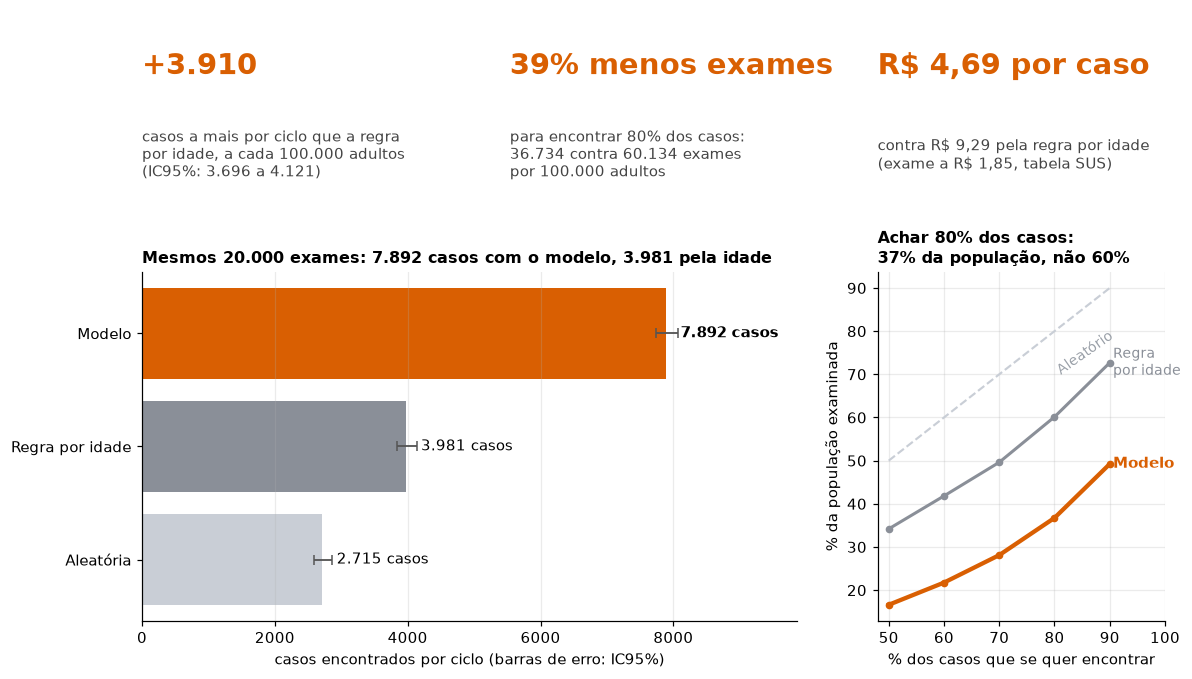

In [17]:
# Painel de impacto: três números grandes e duas comparações (cinza = contexto, laranja = o argumento)
fig = plt.figure(figsize=(12, 7.2))
gs = fig.add_gridspec(2, 3, height_ratios=[0.8, 1.7], hspace=0.38, wspace=0.28)
bans = [
    (f"+{br(extra_casos)}", f"casos a mais por ciclo que a regra\npor idade, a cada {br(POP)} adultos\n(IC95%: {br(lo_e)} a {br(hi_e)})"),
    (f"{economia_pct:.0%} menos exames", f"para encontrar 80% dos casos:\n{br(exames_80_m)} contra {br(exames_80_r)} exames\npor {br(POP)} adultos"),
    (f"R$ {br(impacto.loc['Modelo', 'custo por caso (R$)'], 2)} por caso", f"contra R$ {br(impacto.loc['Regra por idade', 'custo por caso (R$)'], 2)} pela regra por idade\n(exame a R$ {br(CUSTO_EXAME, 2)}, tabela SUS)"),
]
for j, (grande, texto) in enumerate(bans):
    ax_b = fig.add_subplot(gs[0, j]); ax_b.axis("off")
    ax_b.text(0, 0.66, grande, fontsize=19, fontweight="bold", color=LARANJA, va="center")
    ax_b.text(0, 0.12, texto, fontsize=9.5, color="#444", va="center")

ax1 = fig.add_subplot(gs[1, :2])
ordem_est = ["Aleatória", "Regra por idade", "Modelo"]
vals = impacto.loc[ordem_est, "casos encontrados"].to_numpy()
err = np.array([vals - impacto.loc[ordem_est, "IC95% inferior"].to_numpy(), impacto.loc[ordem_est, "IC95% superior"].to_numpy() - vals])
ax1.barh(ordem_est, vals, xerr=err, color=[CLARO, CINZA, LARANJA], ecolor="#555", error_kw={"lw": 1.2, "capsize": 3})
for k, v in zip(ordem_est, vals):
    ax1.text(v + err[1].max() * 0.9 + 60, k, f"{br(v)} casos", va="center", fontsize=10, fontweight="bold" if k == "Modelo" else "normal")
ax1.set_xlim(0, vals.max() * 1.25)
ax1.set_xlabel("casos encontrados por ciclo (barras de erro: IC95%)")
ax1.set_title(f"Mesmos {br(exames_ciclo)} exames: {br(vals[2])} casos com o modelo, {br(vals[1])} pela idade", loc="left", fontsize=10.5)
ax1.grid(axis="y", alpha=0)

ax2 = fig.add_subplot(gs[1, 2])
mt = metas["meta de casos encontrados"].to_numpy() * 100
ax2.plot(mt, mt, color=CLARO, ls="--", lw=1.4)
ax2.plot(mt, metas["% examinada (regra por idade)"] * 100, color=CINZA, lw=2, marker="o", ms=4)
ax2.plot(mt, metas["% da população examinada"] * 100, color=LARANJA, lw=2.8, marker="o", ms=4)
ax2.text(90.6, metas["% da população examinada"].iloc[-1] * 100, "Modelo", color=LARANJA, va="center", fontsize=9.5, fontweight="bold")
ax2.text(90.6, metas["% examinada (regra por idade)"].iloc[-1] * 100, "Regra\npor idade", color=CINZA, va="center", fontsize=9)
ax2.text(80, 70, "Aleatório", color="#9aa0a8", fontsize=9, rotation=35)
ax2.set_xlim(48, 100)
ax2.set_xlabel("% dos casos que se quer encontrar")
ax2.set_ylabel("% da população examinada")
ax2.set_title(f"Achar 80% dos casos:\n{resumo_pop80[0]:.0%} da população, não {resumo_pop80[1]:.0%}", loc="left", fontsize=10.5)
plt.savefig(RES / "06_impacto.png", bbox_inches="tight")
plt.show()

### 6.3 A história para a gestão

**Ideia central (uma frase).** Ordenar a convocação pela nota de risco, em vez de pela idade, encontra milhares de casos a mais com os mesmos exames, ou os mesmos casos com muito menos exames, então a gestão deve adotar a fila por risco e reservar uma ação própria para os adultos de 18 a 44 anos, onde o modelo cobre pouco.

A mesma ideia, com os números da execução, e organizada no arco de três atos:

In [18]:
resumo = {
    "prevalencia": float(y.mean()),
    "idosos_x_jovens": float(idosos / jovens),
    "lift": float(lift_mod),
    "captura": float(cap_mod),
    "captura_regra": float(cap_reg),
    "por_mil_modelo": float(prec_mod * 1000),
    "por_mil_acaso": float(y_te.mean() * 1000),
    "pop_80": resumo_pop80[0],
    "pop_80_regra": resumo_pop80[1],
}
menor_idade = g.loc["idade: 18-44", "cobertura dos casos"]
rr_idx = rr.set_index("fator")["risco relativo"]
top3 = ", ".join(NOMES_PT[v].lower() for v in imp["variável"].head(3))
cobre_sexo = (g.loc["sexo: feminino", "cobertura dos casos"], g.loc["sexo: masculino", "cobertura dos casos"])

big_idea = (f"Ordenar a convocação pela nota de risco, em vez da idade, encontra **{br(extra_casos)} casos a mais por ciclo** a cada {br(POP)} adultos "
            f"com os mesmos {br(exames_ciclo)} exames (ou os mesmos casos com **{economia_pct:.0%} menos exames**): a gestão deve adotar a fila por risco e "
            f"criar uma ação própria para os adultos de 18 a 44 anos, onde o modelo cobre só {menor_idade:.0%} dos casos.")

acao = f"""
1. **Adotar a fila por risco** para a convocação: o primeiro decil tem {tab_dec['prevalência'].iloc[0]:.0%} de diabetes, contra {y_te.mean():.0%} na média.
2. **Dimensionar a capacidade pela meta**: para encontrar 80% dos casos, contratar exames para cerca de **{resumo['pop_80']:.0%}** da população (e não {resumo['pop_80_regra']:.0%}).
3. **Criar uma ação para adultos de 18 a 44 anos** (busca ativa de quem tem IMC e pressão elevados), porque ali o modelo cobre só **{menor_idade:.0%}** dos casos.
4. **Acompanhar a cada ciclo**: casos encontrados por 1.000 exames (hoje o modelo faz {resumo['por_mil_modelo']:.0f}), custo por caso, cobertura por idade, sexo e renda, e quantos convocados comparecem.
5. **Retreinar com dados locais** antes de qualquer uso real.
"""

historia = f"""
> **Ideia central:** {big_idea}

**Ato I: preparação.** Cerca de **{resumo['prevalencia']:.0%}** das pessoas têm diabetes ou pré-diabetes e o programa examina só **20%** da população por ciclo. A prática intuitiva é chamar os mais velhos primeiro. Essa regra encontra **{resumo['captura_regra']:.0%}** dos casos, e alcançar 80% exigiria examinar **{resumo['pop_80_regra']:.0%}** da população.

**Ato II: conflito.** A idade ajuda (a prevalência a partir dos 60 anos é **{resumo['idosos_x_jovens']:.1f}x** a de quem tem até 39), mas não basta: pressão alta multiplica o risco por **{rr_idx['HighBP']:.1f}** e, no modelo, {top3} pesam mais que a idade. Sexo não é a explicação (a cobertura é de {cobre_sexo[0]:.0%} entre mulheres e {cobre_sexo[1]:.0%} entre homens). O ponto fraco está nos adultos de 18 a 44 anos, onde só **{menor_idade:.0%}** dos casos são cobertos.

**Ato III: resolução.** No **cenário inercial** (convocar por idade), {br(exames_ciclo)} exames encontram {br(impacto.loc['Regra por idade', 'casos encontrados'])} casos, a R$ {br(impacto.loc['Regra por idade', 'custo por caso (R$)'], 2)} por caso. Na **intervenção** (convocar pela nota), os mesmos exames encontram **{br(impacto.loc['Modelo', 'casos encontrados'])}** casos, a **R$ {br(impacto.loc['Modelo', 'custo por caso (R$)'], 2)}** por caso. Para a meta de 80% dos casos, são **{br(economia_ex)} exames a menos** por ciclo (R$ {br(economia_ex * CUSTO_EXAME)} a R$ {br(CUSTO_EXAME, 2)} por exame). Plano de ação:
{acao}
"""
display(Markdown(historia))
print(json.dumps(resumo, indent=2))


> **Ideia central:** Ordenar a convocação pela nota de risco, em vez da idade, encontra **3.910 casos a mais por ciclo** a cada 100.000 adultos com os mesmos 20.000 exames (ou os mesmos casos com **39% menos exames**): a gestão deve adotar a fila por risco e criar uma ação própria para os adultos de 18 a 44 anos, onde o modelo cobre só 27% dos casos.

**Ato I: preparação.** Cerca de **14%** das pessoas têm diabetes ou pré-diabetes e o programa examina só **20%** da população por ciclo. A prática intuitiva é chamar os mais velhos primeiro. Essa regra encontra **29%** dos casos, e alcançar 80% exigiria examinar **60%** da população.

**Ato II: conflito.** A idade ajuda (a prevalência a partir dos 60 anos é **6.5x** a de quem tem até 39), mas não basta: pressão alta multiplica o risco por **4.1** e, no modelo, imc, saúde geral autoavaliada, nº de condições de saúde pesam mais que a idade. Sexo não é a explicação (a cobertura é de 57% entre mulheres e 57% entre homens). O ponto fraco está nos adultos de 18 a 44 anos, onde só **27%** dos casos são cobertos.

**Ato III: resolução.** No **cenário inercial** (convocar por idade), 20.000 exames encontram 3.981 casos, a R$ 9,29 por caso. Na **intervenção** (convocar pela nota), os mesmos exames encontram **7.892** casos, a **R$ 4,69** por caso. Para a meta de 80% dos casos, são **23.400 exames a menos** por ciclo (R$ 43.289 a R$ 1,85 por exame). Plano de ação:

1. **Adotar a fila por risco** para a convocação: o primeiro decil tem 47% de diabetes, contra 14% na média.
2. **Dimensionar a capacidade pela meta**: para encontrar 80% dos casos, contratar exames para cerca de **37%** da população (e não 60%).
3. **Criar uma ação para adultos de 18 a 44 anos** (busca ativa de quem tem IMC e pressão elevados), porque ali o modelo cobre só **27%** dos casos.
4. **Acompanhar a cada ciclo**: casos encontrados por 1.000 exames (hoje o modelo faz 395), custo por caso, cobertura por idade, sexo e renda, e quantos convocados comparecem.
5. **Retreinar com dados locais** antes de qualquer uso real.



{
  "prevalencia": 0.13933301797540207,
  "idosos_x_jovens": 6.492101489235935,
  "lift": 2.8319502074688794,
  "captura": 0.5663900414937759,
  "captura_regra": 0.28574122972463223,
  "por_mil_modelo": 394.5605045329129,
  "por_mil_acaso": 139.3356459581625,
  "pop_80": 0.36733943025333754,
  "pop_80_regra": 0.6013350152423
}


### 6.4 Limitações e próximos passos

- **Os dados são dos Estados Unidos** (pesquisa BRFSS 2015) e as respostas são autodeclaradas. Antes de uso no Brasil, o modelo precisa ser reavaliado e treinado com dados locais.
- O alvo reúne diabetes e pré-diabetes, e o estudo é de corte transversal: o modelo **ordena risco**, não diagnostica nem prova causa.
- A nota não é uma probabilidade confiável para decisões individuais; o uso correto é a **ordenação** e o corte por capacidade.
- Há uma queda de cobertura em adultos jovens (critério 3 não atendido). Uma melhoria seria um corte por faixa etária ou um modelo específico para esse grupo.
- **O impacto financeiro é parcial.** Considera só o custo dos exames, com o valor da tabela SUS por exame (sem coleta, logística e convocação). Falta estimar o benefício clínico de achar o caso mais cedo (complicações evitadas), que é o que realmente decide o retorno.
- Próximos passos: calibrar as notas, validar em outro ano da pesquisa, usar o custo real do exame e estimar o benefício clínico para calcular o ROI completo.

In [19]:
conclusao = f"""# Conclusão

**Ideia central.** {big_idea}

**Problema.** Com capacidade para examinar {CAPACIDADE:.0%} da população, quem chamar primeiro para o exame de diabetes.

**Modelo.** {vencedor}, treinado só com respostas de questionário (sem exame de laboratório). Teste com {len(y_te)} pessoas.

| Estratégia | Casos encontrados com {CAPACIDADE:.0%} dos exames | Casos a cada 1.000 examinados |
|---|---:|---:|
| Aleatória | {captura_topo(y_te, nota_acaso)[0]:.1%} | {y_te.mean()*1000:.0f} |
| Regra por idade | {cap_reg:.1%} | {captura_topo(y_te, nota_regra)[1]*1000:.0f} |
| Modelo | {cap_mod:.1%} | {prec_mod*1000:.0f} |

Lift do modelo: {lift_mod:.2f} (IC95% {ic.loc['lift@20%', 'IC95% inferior']:.2f} a {ic.loc['lift@20%', 'IC95% superior']:.2f}). Para encontrar 80% dos casos, examinar {resumo['pop_80']:.1%} da população (regra por idade: {resumo['pop_80_regra']:.1%}).

**Impacto (a cada {br(POP)} adultos, exame a R$ {br(CUSTO_EXAME, 2)}, tabela SUS).**

| Estratégia | Casos encontrados | Custo por caso |
|---|---:|---:|
| Aleatória | {br(impacto.loc['Aleatória', 'casos encontrados'])} | R$ {br(impacto.loc['Aleatória', 'custo por caso (R$)'], 2)} |
| Regra por idade | {br(impacto.loc['Regra por idade', 'casos encontrados'])} | R$ {br(impacto.loc['Regra por idade', 'custo por caso (R$)'], 2)} |
| Modelo | {br(impacto.loc['Modelo', 'casos encontrados'])} | R$ {br(impacto.loc['Modelo', 'custo por caso (R$)'], 2)} |

Casos a mais que a regra por idade: {br(extra_casos)} por ciclo (IC95% {br(lo_e)} a {br(hi_e)}). Para encontrar 80% dos casos: {br(economia_ex)} exames a menos por ciclo ({economia_pct:.0%}).

**Critérios de sucesso.**

{chr(10).join(f"- {r['critério']}: {r['resultado']} ({r['atendido']})" for _, r in criterios.iterrows())}

**Decisão recomendada.**
{acao}
**Limitações.** Dados dos Estados Unidos (2015), autodeclarados, alvo com pré-diabetes e corte transversal. A nota serve para ordenar, não para diagnosticar.
"""
(RES / "CONCLUSAO.md").write_text(conclusao, encoding="utf-8")

2345

In [20]:
meta = {
    "fonte_dados": "UCI 891 - CDC Diabetes Health Indicators",
    "linhas": int(len(bruto)), "variaveis_modelo": FEATURES, "semente": SEED,
    "modelo_escolhido": vencedor,
    "particoes": {"treino": int(len(y_tr)), "validacao": int(len(y_va)), "teste": int(len(y_te))},
    "metricas_teste": {k: float(v) for k, v in teste.loc["Modelo escolhido"].items()},
    "ambiente": {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
                 "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__, "sistema": platform.platform()},
}
if LOCAL.exists():
    meta["sha256_csv"] = hashlib.sha256(LOCAL.read_bytes()).hexdigest()
(RES / "metadados.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print("Arquivos em resultados/:", sorted(p.name for p in RES.iterdir()))

Arquivos em resultados/: ['01_alvo_idade.png', '02_fatores_risco.png', '03_imc_correlacoes.png', '04_ganho_decis.png', '05_importancia_subgrupos.png', '06_impacto.png', 'CONCLUSAO.md', 'capacidade_necessaria.csv', 'decis_de_risco.csv', 'impacto_por_100mil.csv', 'importancia_variaveis.csv', 'intervalos_confianca.csv', 'metadados.json', 'metricas_teste.csv', 'metricas_validacao.csv', 'modelo.joblib', 'particoes.csv', 'sensibilidade_capacidade.csv', 'sensibilidade_custo.csv', 'subgrupos.csv']
